# 1. The episode

An episode is one light curve: the brightness of one star against time. This course
uses the TESS 2-minute cadence. The benchmark hides a transit in most episodes and
nothing in the rest. The detection system, a model with tools, sees only the tools'
outputs. This notebook shows what the tools see.

The first cell loads one episode. It uses the real episode set `data/episodes/s98_v2`
if it is present, and a synthetic light curve with one injected planet otherwise.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["figure.dpi"] = 110

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")

26521 points over 57.4 days; truth kind transit


## The raw light curve

Time is in days from the first point. Flux is divided by its median, so 1.0 is the
star's normal brightness and 0.99 is one percent fainter. A transit is a dip below
1.0 that lasts hours and repeats at one period.

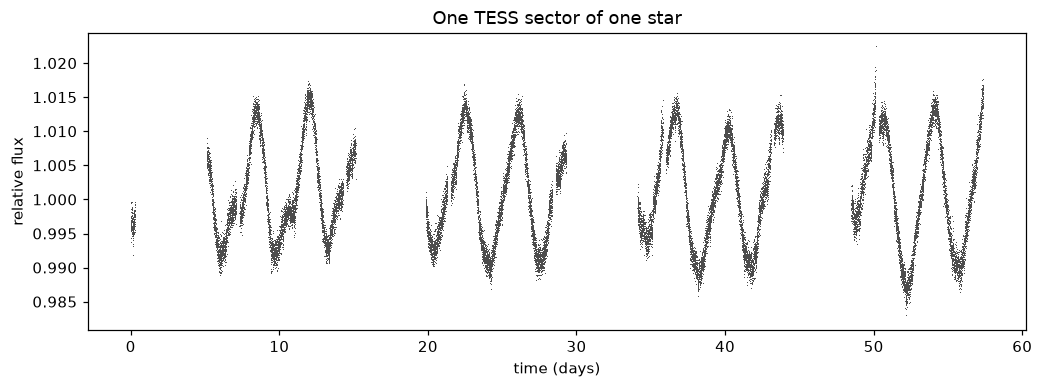

In [2]:
fig, axis = plt.subplots()
axis.plot(time, flux, ",", color="0.3")
axis.set_xlabel("time (days)")
axis.set_ylabel("relative flux")
axis.set_title("One TESS sector of one star")
plt.show()

## What `summarize` reports

The model's first tool call is `summarize`. It returns the numbers below and
nothing else. The point scatter is the white-noise level, in parts per million
(ppm); a transit must be well deeper than it. The flux range tells whether the star
is active: a range far from 1.0 means spots or pulsation, which a period search
can mistake for a planet. The gaps are the breaks in the data, for example the
downlink in the middle of a sector.

In [3]:
from stargazer.tools import summarize

summary = summarize(time, flux)
for key, value in summary.items():
    print(f"{key:20s} {value}")

n_points             26521
span_days            57.372
cadence_minutes      2.0
point_scatter_ppm    1070.6
flux_min             0.982874
flux_max             1.022412
gaps_days            [[0.292, 4.835], [15.136, 4.708], [29.303, 4.8], [43.902, 4.589]]


## The hidden truth

The truth record is hidden from the model. It holds what was injected: the period,
the epoch of one transit centre, the duration and the depth. The plot marks each
injected transit on the light curve, so the reader can compare what the model has
to find with what the eye sees.

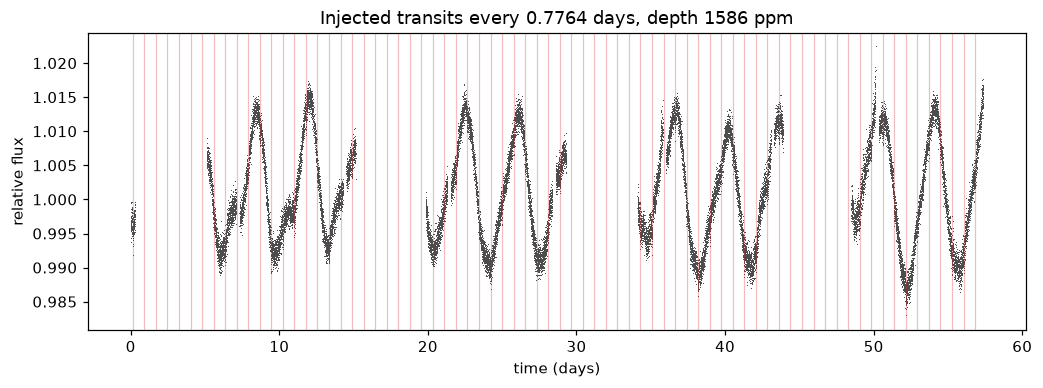

In [4]:
fig, axis = plt.subplots()
axis.plot(time, flux, ",", color="0.3")
if truth["kind"] == "transit":
    transit = truth["transit"]
    n_centres = int((time.max() - transit["t0"]) / transit["period"]) + 1
    centres = transit["t0"] + transit["period"] * np.arange(n_centres)
    for centre in centres:
        axis.axvline(centre, color="tab:red", alpha=0.3, lw=0.8)
    depth_ppm = transit["depth"] * 1e6
    axis.set_title(f"Injected transits every {transit['period']:.4f} days, depth {depth_ppm:.0f} ppm")
else:
    axis.set_title("A null episode: nothing was injected")
axis.set_xlabel("time (days)")
axis.set_ylabel("relative flux")
plt.show()